In [ ]:
%matplotlib inline

%reset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import skfda
import sys

from scipy.integrate import simpson
from skfda.preprocessing.dim_reduction import FPCA
from skfda.representation.basis import BSplineBasis

sys.path.append("[insert root path]/fcpt/functions")
import fNIRSData
import funcChangePoint
import auxFuncChPt


import importlib
importlib.reload(fNIRSData)
importlib.reload(funcChangePoint)
importlib.reload(auxFuncChPt)


Nothing done.


<module 'auxFuncChPt' from '/Users/sambe/Documents/Python_Projects/FDA/functions/auxFuncChPt.py'>

In [ ]:
dataFrame = pd.read_csv('[insert root path]/fcpt/dataRaw/climateData365.csv')
firstYear = 1780
lastYear = 2007

In [207]:
numComponents = 12
numBasis = 12
h = 0
kernelType = "Bartlett"
numBootstrap = 10000
basis = BSplineBasis(n_basis=numComponents)

In [208]:
Year = list(range(1780, 2007))
dataFrame['Year'] = Year
dataFrame = dataFrame.set_index('Year')
dataFrame = dataFrame.loc[firstYear:lastYear] #change this to alter years searched for CPts. i.e.
dataMatrix = dataFrame.to_numpy()
Year = list(range(firstYear, lastYear))
numFuncs = dataMatrix.shape[0]
numDomain = dataMatrix.shape[1]

In [209]:
columnList = ['First Year',
              'Last Year',
              'Change Point',
              'Max. T_N',
              'p-value']

dfChangePoint = pd.DataFrame(columns = columnList)


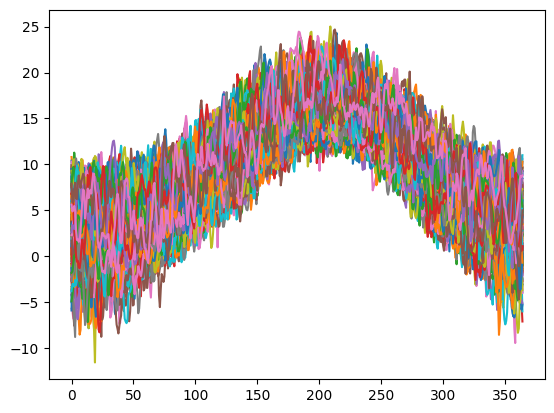

In [210]:
fd = skfda.FDataGrid(
    data_matrix=dataMatrix,
    grid_points = range(numDomain)
)

fd.plot()
print()

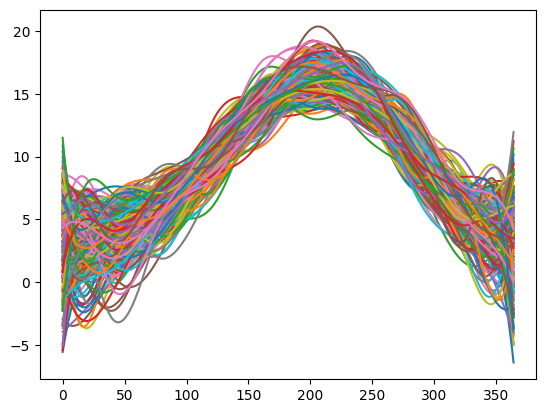

In [211]:
fdObj = fd.to_basis(basis)
fdObj.plot()
print()

In [212]:
chanMat = (auxFuncChPt.findCPtsFF(fdObj, firstYear-Year[0], lastYear-Year[0])).astype('float32')

chanMat = np.delete(chanMat, (0), axis=0)


In [213]:
for i in range(chanMat.shape[0]):
    dfChangePoint = pd.concat([dfChangePoint, pd.DataFrame.from_records([{
        'First Year':(chanMat[i][0] + Year[0]),
        'Last Year': (chanMat[i][1] + Year[0]),
        'Change Point': (chanMat[i][2] + Year[0]),
        'Max. T_N': (chanMat[i][3]),
        'p-value': (chanMat[i][4])
        }])])

In [214]:
dfChangePoint

,First Year,Last Year,Change Point,Max. T_N,p-value
0,1780.0,2007.0,1893.0,156.456757,0.0011
0,1780.0,1892.0,1842.0,49.711178,0.4958
0,1893.0,2007.0,1927.0,42.647404,0.5781


In [215]:
#save the participant's nested dictionary
#with open(outputFilename, 'wb') as f:
#    pickle.dump(dfChangePoint, f)

In [216]:
df = dfChangePoint[dfChangePoint['p-value'] <= 0.05]
df

,First Year,Last Year,Change Point,Max. T_N,p-value
0,1780.0,2007.0,1893.0,156.456757,0.0011


In [217]:
dfChan = df.sort_values(by=['Change Point'])

changeColumn = (dfChan.get('Change Point').tolist())
changeColumn = [int(x) for x in changeColumn]
changeColumn.append(lastYear + 1)

In [218]:
iBlock = 0
tempFunc = 0

blockMeans = np.empty([len(changeColumn), len(range(numDomain))])


In [219]:
for point in changeColumn:
    firstFunc= tempFunc
    lastFunc = point-Year[0] - 1 #-1 because dataMatrix rows go from 0->(numTrials-1)
    blockMatrix = dataMatrix[firstFunc:lastFunc, ]
    blockMeans[iBlock] = np.mean(blockMatrix, axis = 0)
    tempFunc = point-Year[0]
    iBlock = iBlock + 1


<Axes: >

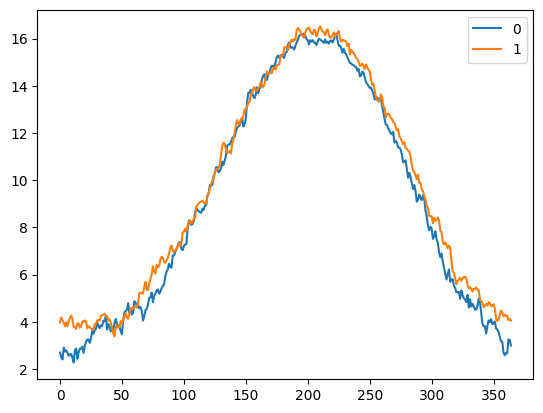

In [220]:
trialFrame = pd.DataFrame(data=blockMeans)
trialFrame = trialFrame.T

trialFrame.plot()